# 사출신호별 P1 압력 하락 시각화 (2026-10-06)

**질문**: P1 압력(`Scale_Out___PT_P1`)이 사출 신호 앞뒤 2틱 경계 안에서 유의미하게 떨어졌는가 — 그리고 어떤 사출 신호가 그 하락을 가장 잘 설명하는가.

- 기간: 10/02(금) 07:00~11:30, 10/06(화) 07:00~18:38. 캐시 `parkkt/cache/inj_dip_p1_{fri,today}.pkl` (`code_ongoing/inj_dip_signal_pull.py`)
- 신호: S1 `Shot_Injection_HD1_P1` / S2 `Shot_Injection_On_HD1` / S3 `HD1_FOAMING_SHOT1~4`(번호마다 별도 이벤트) / S4 `S2 ∧ SHOTk`
- 세 신호는 **포함관계** S1 ⊂ S2 ⊂ FOAMING (두 날 100%) 라서 S2∪FOAMING = FOAMING. 그래서 S4는 S2를 FOAMING 번호별로 쪼갠 것으로 정의.

### 정의
- **이벤트 하락 %** = (신호 시작 직전 2틱 평균 − [신호 ON ~ 끝+2틱] 중 최저) / 직전 2틱 평균
- **틱 하락 %** = (직전 2틱 평균 − 현재 틱) / 직전 2틱 평균
- **BuildUp OFF 는 제외**: 기준 2틱도, 응답 틱도 BuildUp=1 이고 같은 사이클인 틱만 쓴다. 응답창이 BuildUp OFF 로 넘어가면 그 부분은 잘라낸다 (펌프가 꺼지며 압력이 ~65 로 떨어지는 건 사출 하락이 아니므로).
- **비교군(null)**: 같은 방식으로 재되, 창 전체(앞 2틱 ~ 뒤 2틱)에 **S2(헤드 사출)가 한 번도 없는** 펌프 가동 위치. 즉 "사출이 없을 때도 압력이 이 정도는 흔들린다"의 분포.


In [1]:
import sys, os
# 저장소 루트(Log_Extractor.py 가 있는 곳)를 찾아 이동 — 어느 폴더에서 열든, 몇 번을 실행하든 같은 결과
_d = os.path.abspath(os.getcwd())
while not os.path.exists(os.path.join(_d, 'Log_Extractor.py')):
    if os.path.dirname(_d) == _d:
        raise FileNotFoundError('저장소 루트(Log_Extractor.py)를 찾지 못했습니다. 노트북을 KTA_Train 폴더 안에서 열어 주세요.')
    _d = os.path.dirname(_d)
os.chdir(_d)
_code = os.path.join(_d, 'parkkt', 'code_ongoing')
if _code not in sys.path:
    sys.path.insert(0, _code)
from inj_dip_signal_viz import *
dfs, evs = {}, {}
for n in ['fri', 'today']: dfs[n], evs[n] = prepare(n)
qd = np.concatenate([d.d_t[d.quiet].values for d in dfs.values()])
thr, thr_big = np.percentile(qd, 95), np.percentile(qd, 99)
nullL = null_events(dfs.values())
thr_ev = np.percentile(np.concatenate([nullL[3], nullL[4]]), 95)
print(f'비교군 틱 n={len(qd)}  ->  유의 하락(P95) {thr:.2f}%   강한 하락(P99) {thr_big:.2f}%')
print(f'비교군 이벤트(응답 3~4틱) n={len(nullL[3])+len(nullL[4])}  ->  이벤트 유의 기준(P95) {thr_ev:.2f}%')

비교군 틱 n=1475  ->  유의 하락(P95) 3.63%   강한 하락(P99) 5.26%
비교군 이벤트(응답 3~4틱) n=2270  ->  이벤트 유의 기준(P95) 4.80%


## 1. 유의미한 하락은 몇 % 인가

사출이 없을 때(비교군)의 하락 분포에서 **상위 5% 경계(P95)** 를 "유의", **상위 1%(P99)** 를 "강한" 하락으로 잡았다.
"사출이 없었다면 이만큼 떨어질 확률이 5%(1%)밖에 안 된다"는 뜻이다. P1 압력이 ~100 이고 눈금이 1 이라 5% ≈ 4~6 눈금.

In [2]:
rows = []
for p in [50, 75, 90, 95, 99]:
    rows.append({'분위': f'P{p}', '틱 하락 %': np.percentile(qd, p),
                 '이벤트 하락 % (응답 3~4틱)': np.percentile(np.concatenate([nullL[3], nullL[4]]), p)})
pd.DataFrame(rows).set_index('분위').round(2)

,틱 하락 %,이벤트 하락 % (응답 3~4틱)
분위,,
P50,-0.47,1.36
P75,1.29,2.80
P90,2.72,3.96
P95,3.63,4.80
P99,5.26,6.01


## 2. 실제 사이클에서 각 S 가 하락을 잡은 모습

위: P1 압력. 큰 점 = 유의 하락 틱(≥3.6%), 색 = 그 틱이 어느 신호 창 안이었는지 (겹치면 S1 → S2 → FOAMING 순으로 귀속).
아래: 신호 레인. 진한 막대 = 신호 ON, 연한 막대 = 뒤 2틱 응답창. 회색 = BuildUp OFF(분석 제외).

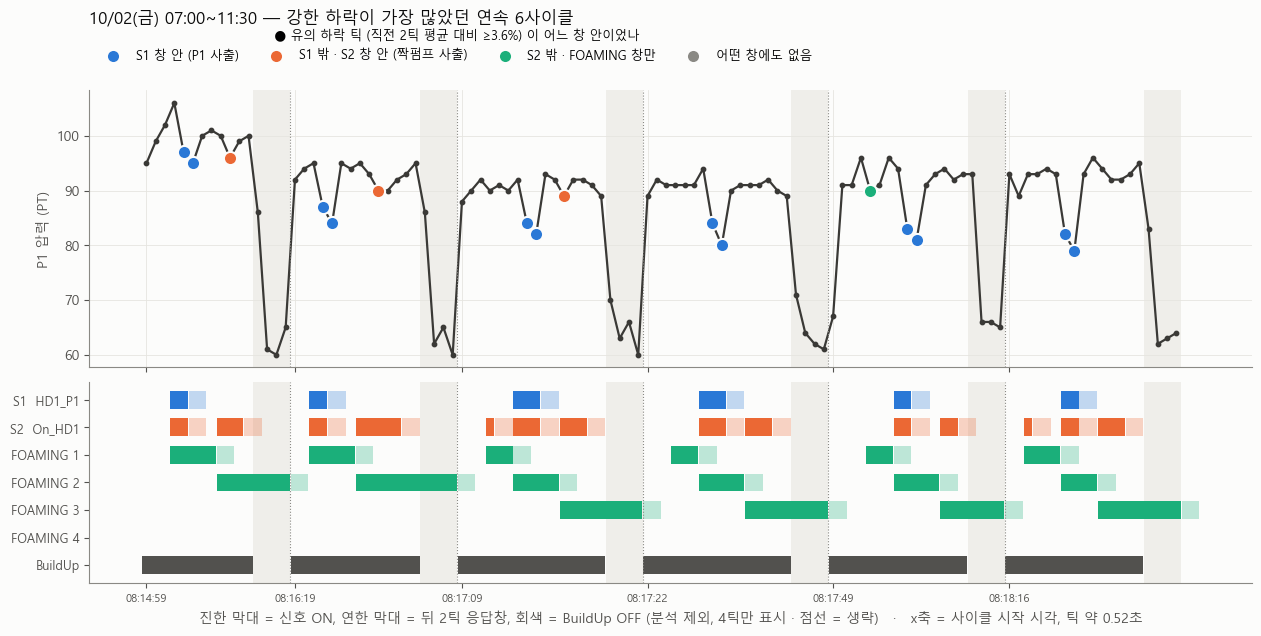

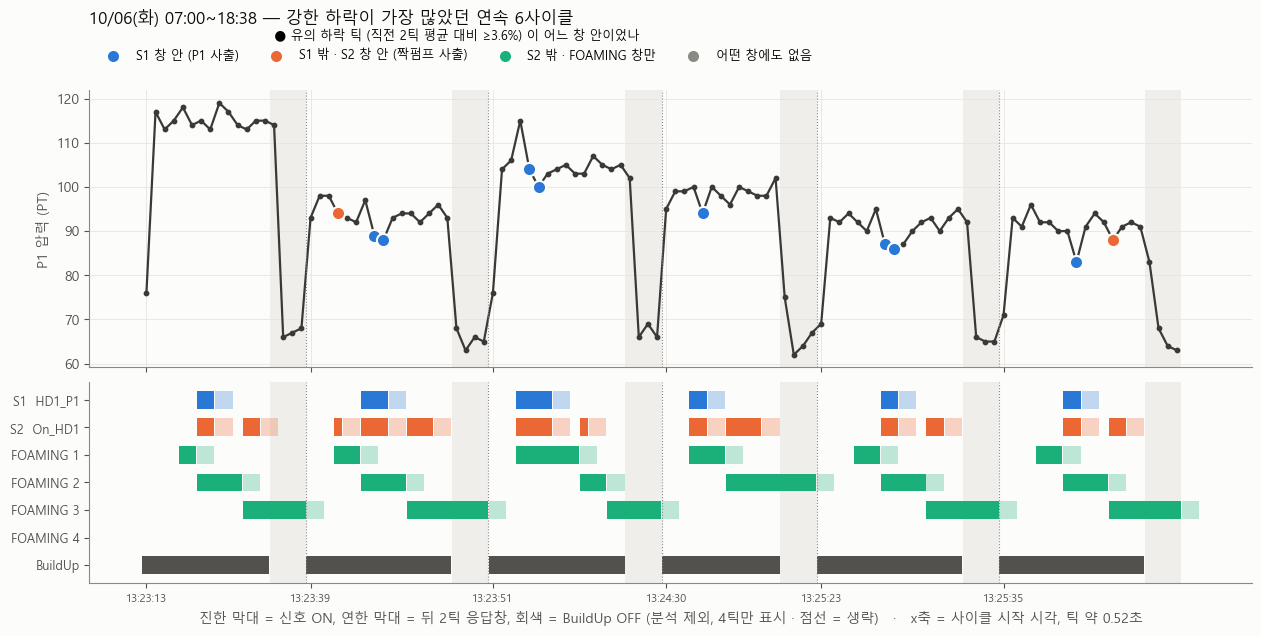

In [3]:
fig_timeline(dfs['fri'], thr, thr_big, f"{DAYS['fri']} — 강한 하락이 가장 많았던 연속 6사이클"); plt.show()
fig_timeline(dfs['today'], thr, thr_big, f"{DAYS['today']} — 강한 하락이 가장 많았던 연속 6사이클"); plt.show()

**읽는 법**: 사이클마다 S1(파랑) 직후 압력이 2~3틱 꺼지고, 그 점들이 파랑이다. S2 는 사이클당 2~3번 켜지는데 FOAMING 3 단계에서 켜지는 S2(S1 없음, 같은 헤드 짝펌프 사출로 추정) 뒤에는 P1 압력이 거의 안 떨어진다.
아래 셀에서 `pick=` 에 사이클 번호를 주면 아무 구간이나 볼 수 있다.

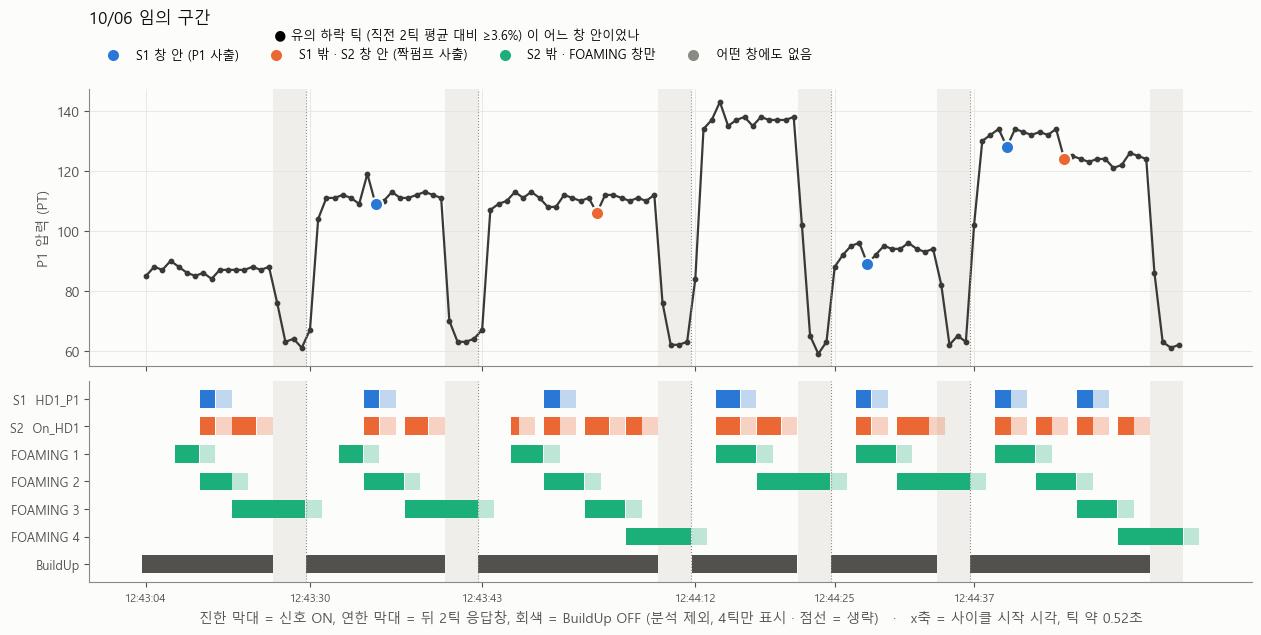

In [4]:
# 임의 구간 보기: pick = 몇 번째 사이클부터 (0 ~ )
fig_timeline(dfs['today'], thr, thr_big, '10/06 임의 구간', n_cyc=6, pick=800); plt.show()

## 3. 사이클 안 위치별로 모아 보면

위: 틱 위치별 압력(사이클 중앙값=100). 가운데: 그 위치에서 유의 하락이 난 틱 비율(색 = 누구 창). 아래: 그 위치에서 각 신호가 켜져 있는 비율.
**압력 P10 이 꺼지는 tick 4~5, 7~8 = S1 이 켜지는 위치**. tick 9~13 은 S2 가 50~70% 켜져 있는데도 하락이 드물다(주황).

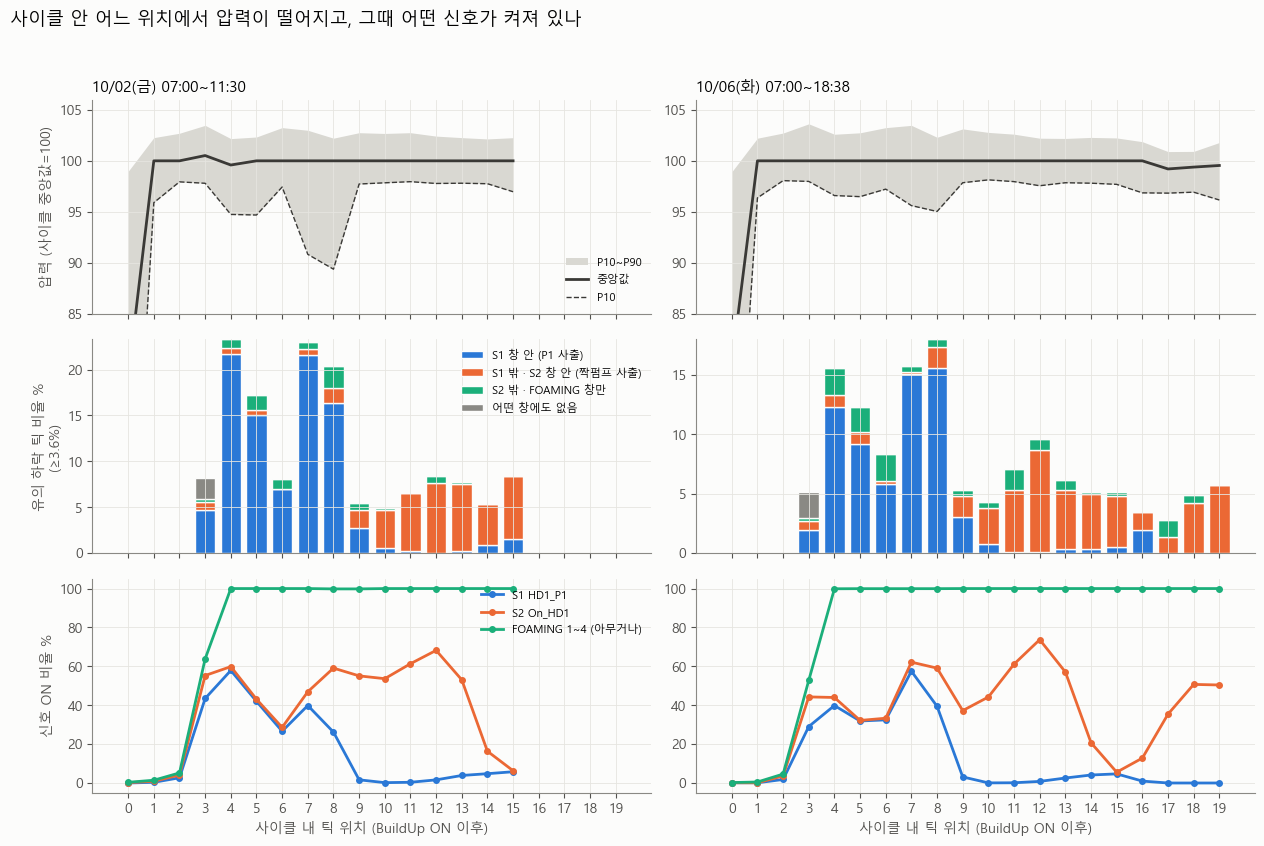

In [5]:
fig_tick_profile(dfs, thr); plt.show()

## 4. 유의 하락 틱은 누구 창 안에서 났나

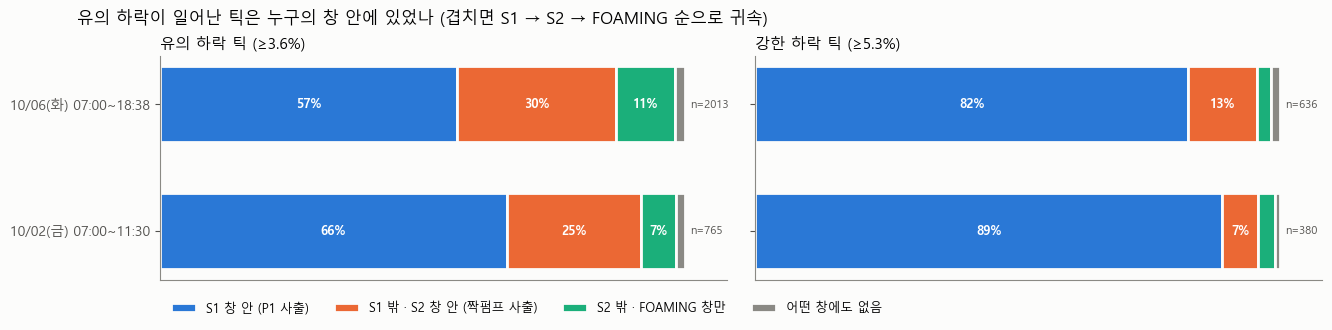

In [6]:
fig_share(dfs, thr, thr_big); plt.show()

## 5. AUC 는 무엇을 비교하나

회색 = 비교군(사출 없는 위치)의 하락 분포, 색선 = 그 신호 이벤트의 하락 분포.
**AUC = 그 신호 이벤트 하나와 비교군 위치 하나를 무작위로 뽑았을 때, 신호 쪽 하락이 더 클 확률.**
- 0.5 = 동전던지기 (신호가 있으나 없으나 하락 크기가 같다) — S3 SHOT3 가 정확히 이 경우
- 1.0 = 신호 이벤트가 항상 더 많이 떨어진다
- 비교군은 응답창 길이(L)를 맞춰 비교한다 (창이 길수록 최저값이 낮게 나올 기회가 많아서)

S1 은 0.66~0.71 — 오른쪽으로 긴 꼬리(5~15% 하락)가 있어서다. 다만 S1 이벤트의 절반 정도는 비교군과 비슷한 크기(0~4%)라 **"S1 이 켜지면 항상 떨어진다"는 아니다**.

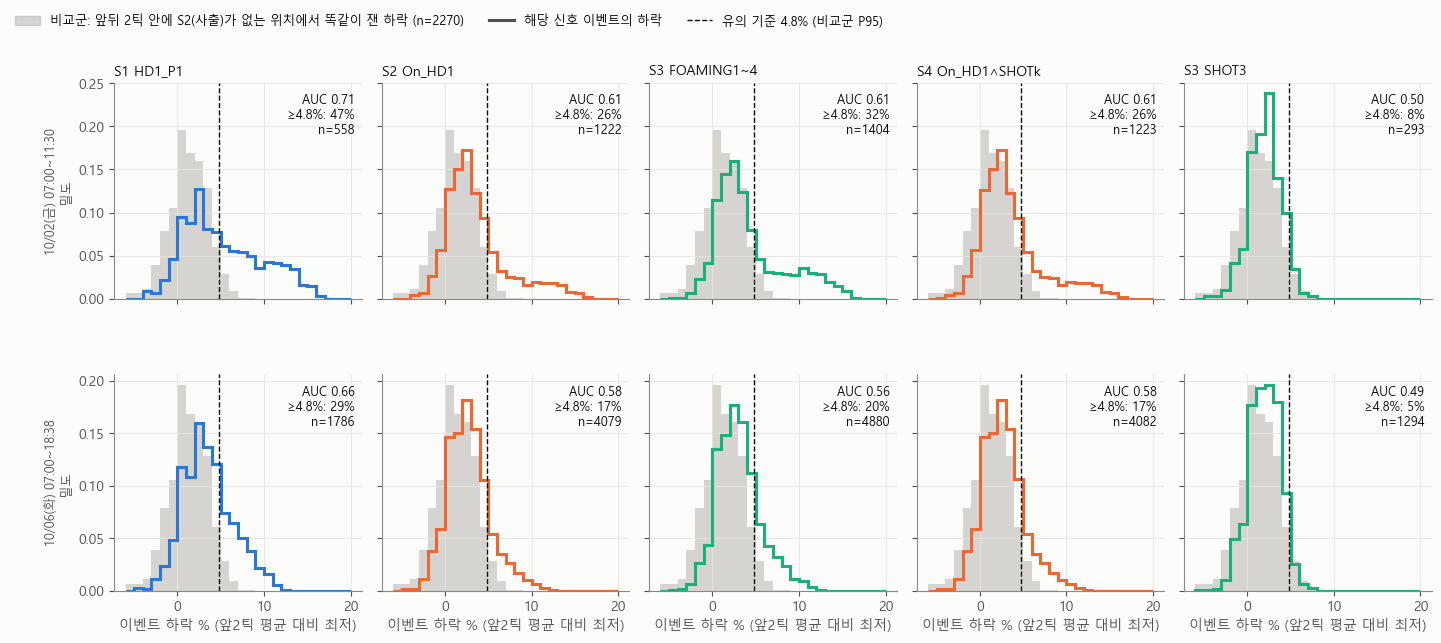

In [7]:
fig_auc(evs, nullL, thr_ev); plt.show()

## 6. BuildUp OFF 제외가 얼마나 영향이 있었나

응답창(신호 ~ 끝+2틱)이 BuildUp OFF 로 넘어간 이벤트 수와, 자르지 않았다면 하락이 얼마로 잡혔을지.

In [8]:
rows = []
for n, d in dfs.items():
    for nm, cr in d.attrs['cross'].items():
        if nm.startswith('S3 SHOT'): continue
        rows.append({'날짜': DAYS[n], '신호': nm, '평가 이벤트': len(evs[n][nm]), 'OFF 경계 걸침': len(cr),
                     '잘랐을 때 하락 중앙%': np.nanmedian(cr[:, 0]) if len(cr) else np.nan,
                     '안 잘랐으면 하락 중앙%': np.median(cr[:, 1]) if len(cr) else np.nan})
pd.DataFrame(rows).round(1)

,날짜,신호,평가 이벤트,OFF 경계 걸침,잘랐을 때 하락 중앙%,안 잘랐으면 하락 중앙%
0,10/02(금) 07:00~11:30,S1 HD1_P1,558,1,11.5,30.1
1,10/02(금) 07:00~11:30,S2 On_HD1,1222,182,2.1,3.7
2,10/02(금) 07:00~11:30,S3 FOAMING1~4,1404,561,2.1,37.8
3,10/02(금) 07:00~11:30,S4 On_HD1∧SHOTk,1223,182,2.1,3.7
4,10/06(화) 07:00~18:38,S1 HD1_P1,1786,0,NaN,NaN
5,10/06(화) 07:00~18:38,S2 On_HD1,4079,533,2.1,3.3
6,10/06(화) 07:00~18:38,S3 FOAMING1~4,4880,1775,2.2,40.9
7,10/06(화) 07:00~18:38,S4 On_HD1∧SHOTk,4082,533,2.1,3.3


FOAMING 은 BuildUp 이 꺼진 뒤에도 이어지는 단계(2·3·4)가 있어서 이벤트의 약 40% 가 경계를 넘는다. 안 잘랐으면 그 이벤트들이 펌프 정지 하락(~40%)으로 "엄청난 하락"처럼 잡혀 FOAMING 이 가장 잘 설명하는 신호로 착각됐을 것이다.

### 한계
- 모든 사이클에 사출이 있어(사출 없는 사이클 2~5개) 비교군이 사이클 앞/뒤쪽 틱에 몰려 있다 — 위치 효과가 섞일 수 있다.
- 긴 응답창(FOAMING, 7~14틱)은 비교군 표본이 부족해 5~6틱 비교군으로 대신 비교 → FOAMING 쪽에 유리한(보수적인) 비교.